# Drift monitoring: is the model still seeing the world it learned from?

We want to monitor if the input structure stays the same over time, because if it doesn't, it is an early warning sign that we may need to redo and update the model. 

This notebook:

1. explains the Population Stability Index (PSI), the standard drift
   measure in credit and fraud;
2. tracks PSI across the two days in the data, in 4-hour windows;
3. shows why a calendar feature like hour of day raises false alarms, and
   how to avoid them;
4. checks real performance per window, once labels are in.

It uses the model and drift reference saved by `01_train_and_decide.ipynb`.

## 1. Setup

Same imports as before, plus the drift functions from
`src/monitoring.py`.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBClassifier

ROOT = Path.cwd().parent
sys.path.append(str(ROOT))
from src.features import FEATURES, add_hour_of_day, flag_for_review
from src.monitoring import make_edges, share_per_bin, psi, drift_report
from src.monitoring import build_reference, WATCH_LEVEL, ALERT_LEVEL

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

Load the saved model and its model card. The card holds the drift
reference: how each watched column was spread across bins in training.

In [2]:
model = XGBClassifier()
model.load_model(ROOT / "artifacts" / "model.json")
with open(ROOT / "artifacts" / "model_card.json") as f:
    card = json.load(f)

reference = card["drift_reference"]
REVIEW_COST = card["review_cost_eur"]
watched = list(reference)
print("Model version:", card["model_version"])
print("Training ended at hour:", card["train_end_hour"])
print("Watched columns:", watched)

Model version: xgb-plain-v1
Training ended at hour: 32
Watched columns: ['score', 'Amount', 'hour_of_day', 'V14', 'V10', 'V12', 'V4', 'V17']


## 2. Rebuild the data exactly as in training

The same three steps as notebook 01: drop exact duplicate rows (the same
payment logged twice), add `hour_of_day`, and sort by time.

In [3]:
raw = pd.read_csv(ROOT / "data" / "creditcard.csv")
data = raw.drop_duplicates(keep="first")
data = add_hour_of_day(data)
data = data.sort_values("Time", kind="stable").reset_index(drop=True)
print("Shape:", data.shape)
data[["Time", "hour_of_day", "Amount", "Class"]].head()

Shape: (283726, 32)


,Time,hour_of_day,Amount,Class
0,0.0,0,149.62,0
1,0.0,0,2.69,0
2,1.0,0,378.66,0
3,1.0,0,123.50,0
4,2.0,0,69.99,0


Now we score every payment with the saved model and add two columns:
`score` (fraud probability) and `hour` (hours since the start), which we
use to cut the data into windows. `review` is the amount-aware decision.

In [4]:
data["score"] = model.predict_proba(data[FEATURES])[:, 1]
data["hour"] = data["Time"] / 3600
data["review"] = flag_for_review(data["score"].values,
                                 data["Amount"].values)
data[["hour", "Amount", "score", "review", "Class"]].tail()

,hour,Amount,score,review,Class
283721,47.996111,0.77,0.000008,False,0
283722,47.996389,24.79,0.000013,False,0
283723,47.996667,67.88,0.000019,False,0
283724,47.996667,10.00,0.000022,False,0
283725,47.997778,217.00,0.000956,False,0


## 3. What PSI measures

**Intuition.** Imagine sorting the training payments into 10 jars by
amount, with the jars sized so that each holds 10% of them. Now pour
today's payments into the same jars. If each jar again gets about 10%,
nothing has changed. If some jars overflow and others sit empty, the
amounts have shifted. PSI adds up how uneven the jars are.

**The math.** With $r_i$ the share of training data in jar $i$ and $n_i$
the share of new data:

$$\text{PSI} = \sum_i (n_i - r_i)\,\ln\frac{n_i}{r_i}$$

**Rules of thumb** used in credit risk: below 0.10 is stable, 0.10 to 0.25
is worth watching, above 0.25 is a real shift.

Let's do it by hand for `Amount`, comparing the training period with the
test period (hours 40 to 48).

In [5]:
train_part = data[data["hour"] < card["train_end_hour"]]
test_part = data[data["hour"] >= card["valid_end_hour"]]

edges = make_edges(train_part["Amount"].values)
jars = pd.DataFrame({
    "from_eur": edges[:-1].round(2),
    "to_eur": edges[1:].round(2),
    "train_share": share_per_bin(train_part["Amount"].values, edges),
    "test_share": share_per_bin(test_part["Amount"].values, edges),
})
jars.round(3)

,from_eur,to_eur,train_share,test_share
0,-inf,1.00,0.058,0.068
1,1.00,3.30,0.142,0.150
2,3.30,8.50,0.100,0.107
3,8.50,12.98,0.100,0.108
4,12.98,21.40,0.100,0.100
5,21.40,36.29,0.100,0.099
6,36.29,59.15,0.100,0.098
7,59.15,99.99,0.099,0.091
8,99.99,200.00,0.100,0.089
9,200.00,inf,0.101,0.092


Each training jar holds about 10%. Now we apply the formula to the two
share columns.

In [6]:
by_hand = psi(jars["train_share"], jars["test_share"])
print("PSI for Amount, train vs test: %.4f" % by_hand)

PSI for Amount, train vs test: 0.0062


The test-period jars stay within about one percentage point of training,
so PSI is 0.006: payment amounts are stable.

## 4. PSI over time, in 4-hour windows

In production we would run this check on a schedule, for example every
few hours. Here we replay the two days: 12 windows of 4 hours each. For
each window, `drift_report` computes PSI for every watched column against
the training reference. We collect the results in `psi_table`, with one
row per column and one column per window.

In [7]:
WINDOW_HOURS = 4
window_starts = list(range(0, 48, WINDOW_HOURS))
columns = {}
for start in window_starts:
    end = start + WINDOW_HOURS
    in_window = (data["hour"] >= start) & (data["hour"] < end)
    report = drift_report(reference, data[in_window])
    label = "%02d-%02d" % (start, end)
    columns[label] = report.set_index("column")["psi"]

psi_table = pd.DataFrame(columns).loc[watched]
print("Shape:", psi_table.shape)
psi_table.round(2)

Shape: (8, 12)


,00-04,04-08,08-12,12-16,16-20,20-24,24-28,28-32,32-36,36-40,40-44,44-48
column,,,,,,,,,,,,
score,0.04,0.03,0.04,0.02,0.02,0.00,0.01,0.02,0.01,0.14,0.10,0.04
Amount,0.04,0.06,0.03,0.02,0.00,0.01,0.07,0.14,0.02,0.01,0.00,0.02
hour_of_day,7.43,6.90,5.55,6.31,6.88,6.72,7.44,6.87,5.55,6.32,6.88,6.72
V14,0.63,0.61,0.17,0.15,0.14,0.12,0.62,0.72,0.14,0.10,0.14,0.12
V10,0.13,0.11,0.02,0.01,0.01,0.00,0.12,0.10,0.09,0.08,0.06,0.06
V12,0.84,0.81,0.27,0.29,0.31,0.39,0.88,0.81,0.29,0.30,0.30,0.36
V4,0.04,0.04,0.00,0.01,0.01,0.01,0.13,0.18,0.17,0.16,0.20,0.23
V17,0.16,0.24,0.01,0.01,0.01,0.02,0.06,0.02,0.05,0.05,0.05,0.08


The same table as a heat map. Dark cells are windows where a column looks
very different from training. The dashed line marks the end of training:
windows to its left overlap the training data.

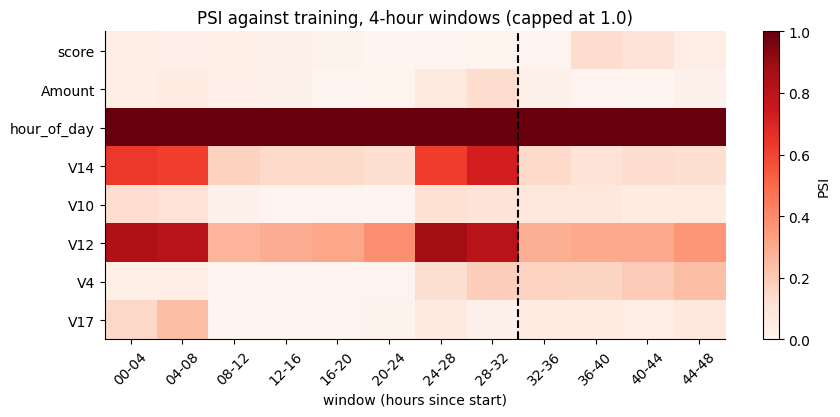

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
shown = psi_table.clip(upper=1.0)
image = ax.imshow(shown.values, cmap="Reds", vmin=0, vmax=1.0,
                  aspect="auto")
ax.set_xticks(range(len(shown.columns)))
ax.set_xticklabels(shown.columns, rotation=45)
ax.set_yticks(range(len(shown.index)))
ax.set_yticklabels(shown.index)
train_windows = card["train_end_hour"] / WINDOW_HOURS
ax.axvline(train_windows - 0.5, color="black", linestyle="--")
ax.set_xlabel("window (hours since start)")
ax.set_title("PSI against training, 4-hour windows (capped at 1.0)")
fig.colorbar(image, ax=ax, label="PSI")
fig.savefig(ROOT / "docs" / "images" / "psi_heatmap.png", dpi=120,
            bbox_inches="tight")
plt.show()

Three things stand out. `hour_of_day` is dark in every window; and it is expected because the data is not randomized on hour_of_day, and in training data we have night data that in the test data we don't. `V14` and `V12` light up in the night
windows (00-08 and 24-32) even inside the training period, so they follow
the clock too. And `V4` creeps up across day two, from 0.13 to 0.23: the
one pattern that is not simply night versus day.

## 5. The hour-of-day false alarm

A 4-hour window only ever contains 4 of the 24 hours, while the training
data contains all of them. So `hour_of_day` will *always* look like it
has drifted in a short window. That is not a change in the world. It is
just the clock. The heat map suggests `V12` and `V14` follow the clock
too.

**The fix:** compare like with like. Compare the last 8 hours with the
**same 8 hours of the day before**, not with all of training.

Here the test period, hours 40 to 48, is compared with hours 16 to 24 of
day one. We build a reference from those 8 hours with the same
`build_reference` function.

In [9]:
yesterday = data[(data["hour"] >= 16) & (data["hour"] < 24)]
today = data[(data["hour"] >= 40) & (data["hour"] < 48)]
print("Yesterday 16-24:", yesterday.shape, " Today 40-48:", today.shape)

ref_same_hours = build_reference(yesterday, watched)
vs_training = drift_report(reference, today).set_index("column")
vs_yesterday = drift_report(ref_same_hours, today).set_index("column")

side_by_side = pd.DataFrame({
    "psi_vs_all_training": vs_training["psi"],
    "psi_vs_same_hours_yesterday": vs_yesterday["psi"],
}).loc[watched]
side_by_side.round(3)

Yesterday 16-24: (65956, 35)  Today 40-48: (59690, 35)


,psi_vs_all_training,psi_vs_same_hours_yesterday
column,,
score,0.072,0.048
Amount,0.006,0.004
hour_of_day,4.658,0.020
V14,0.130,0.106
V10,0.059,0.095
V12,0.321,0.011
V4,0.213,0.249
V17,0.060,0.052


Against the same hours yesterday, the `hour_of_day` false alarm
disappears (4.66 to 0.02), and so does `V12`'s (0.32 to 0.01): its
"drift" was just night versus day. `V4` stays near 0.25 either way. It is
the one input that has really changed, and the one to keep an eye on.

## 6. Watching the score itself

Of all the watched columns, the model's own score is the most useful: it
summarises every input the way the model sees it. We plot its PSI per
window and draw the watch and alert levels.

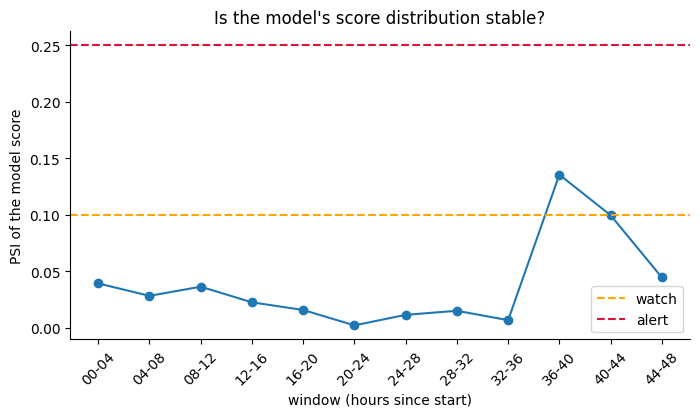

In [10]:
score_psi = psi_table.loc["score"]
fig, ax = plt.subplots()
ax.plot(score_psi.index, score_psi.values, marker="o")
ax.axhline(WATCH_LEVEL, color="orange", linestyle="--", label="watch")
ax.axhline(ALERT_LEVEL, color="crimson", linestyle="--", label="alert")
ax.set_xlabel("window (hours since start)")
ax.set_ylabel("PSI of the model score")
ax.set_title("Is the model's score distribution stable?")
ax.tick_params(axis="x", rotation=45)
ax.legend()
plt.show()

The score stays below the watch level in every window except 36-40,
where it touches 0.14 before settling again. Even with some inputs moving,
the model's overall view of the payments is stable over the two days.

## 7. Once the labels arrive: real performance per window

Weeks later the chargebacks come in and we can check what actually
happened. We use 8-hour windows so that each one has enough frauds to
say something.

For each window we record: payments, frauds, payments sent to review, the
share of fraud money caught, and the saving against approving everything.
Windows before hour 32 overlap the training data, so they flatter the
model; we label them.

In [11]:
rows = []
for start in range(0, 48, 8):
    w = data[(data["hour"] >= start) & (data["hour"] < start + 8)]
    fraud = w["Class"] == 1
    fraud_eur = w.loc[fraud, "Amount"].sum()
    caught_eur = w.loc[fraud & w["review"], "Amount"].sum()
    cost = REVIEW_COST * w["review"].sum() + fraud_eur - caught_eur
    rows.append({
        "window": "%02d-%02d" % (start, start + 8),
        "period": "train" if start < card["train_end_hour"] else "unseen",
        "payments": len(w),
        "frauds": int(fraud.sum()),
        "reviews": int(w["review"].sum()),
        "fraud_eur_caught_%": round(100 * caught_eur / fraud_eur, 1),
        "saving_vs_no_model_eur": round(fraud_eur - cost),
    })
performance = pd.DataFrame(rows).set_index("window")
performance

,period,payments,frauds,reviews,fraud_eur_caught_%,saving_vs_no_model_eur
window,,,,,,
00-08,train,17484,81,40,99.3,7687
08-16,train,60796,110,97,99.5,9690
16-24,train,65956,81,71,99.8,13910
24-32,train,17673,66,51,99.5,5587
32-40,unseen,62127,59,88,62.1,6927
40-48,unseen,59690,76,73,70.9,5589


Inside the training period the model catches over 99% of fraud money.
It has seen those exact frauds, so those numbers flatter it and should
never be reported. On the unseen hours it catches 62% to 71% of fraud
money and still saves about €5,600 to €6,900 per 8 hours against having
no model. The gap between the two is why we test on the future.

## 8. The recommended report for the test period

Following section 5, the recommended check compares the window with the
same hours of the day before. In practice a scheduler would run it, not
a notebook. Here is the report for the test period:

In [12]:
report = drift_report(ref_same_hours, today)
report

,column,psi,status
0,V4,0.2493,watch
1,V14,0.1057,watch
2,V10,0.0947,ok
3,V17,0.0522,ok
4,score,0.0476,ok
5,hour_of_day,0.0199,ok
6,V12,0.0110,ok
7,Amount,0.0042,ok


Nothing reaches "alert"; `V4` and `V14` are on "watch". Compared with all
of training instead, `V12` would have raised an alert, and it would have
been a false one.

## 9. Recap

- **PSI** compares how a column is spread today with a reference. Above
  0.25 means a real shift.
- **Short windows compared with all of training raise false alarms** for
  anything that follows the clock: `hour_of_day`, and here `V12` and
  `V14`.
- **Compare with the same hours yesterday** instead. That removes the
  false alarms and leaves `V4`, the one input that really moved on day
  two.
- **The model's score stayed stable** across all 12 windows.
- **Once the labels arrive**, the model catches 62% to 71% of fraud money
  on hours it never saw. The 99% on training hours is not a real result.